<div style="text-align: center; font-style: italic; font-size: 18px">Water Resources Management</div>
<div></div>
<div style="text-align: center">Supplementary Information of</div>
<div style="text-align: center; font-weight: bold; font-size: 24px">Data-Driven Leak Localization Modeling for Optimal Sensor Placement</div>

---

Maria Gloria Di Chiano<sup>1*</sup>, Dennis Zanutto<sup>2,3</sup>, Gianfranco Becciu<sup>1</sup>, Dragan Savić<sup>3,4</sup>

<sup>1</sup>D.I.C.A. Politecnico di Milano, 20133 Milano, Italy

<sup>2</sup>D.E.I.B, Politecnico di Milano, 20133, Milano, Italy

<sup>3</sup>KWR Water Research Institute, Nieuwegein, 3430 BB, the Netherlands

<sup>4</sup>Centre for Water Systems, University of Exeter, Exeter, EX4 4QF, United Kingdom


## Content of this File

- Text S3

## Introduction
This notebook tests whether the settings proposed by Alves et al. for their leak signature matrix (LSM) reconstruction method are optimal, or whether specific choices can change leak localization (LL) performances of this method.

In [1]:
# Imports
from wdn_osp_ll.sensor_placement_optimization import load_or_compute
from wdn_osp_ll.visualization import (
    plot_pareto_front_nsensors_msa,
    plot_hypervolume_bar,
    plot_hypervolume_trajectory,
)

### Text S3 - Impact of Scenario-based Scaling and Choice of the Leak Signature Matrix

The goal of this comparison is to test the Leak Localization method proposed by Alves et al. with alternative configurations on the Hanoi network.
Specifically, building on the knowledge gained while the testing Boatwright LL methodology, we test wheter using the chi-squared as LSM instead of the Sensitivity Matrix as used in the work by Alves et al. can improved leak localization perfromance.

In [2]:
suggested_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "sensitivity",
            "scale_nodes_by_scenario_mean": False,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "alves",
                    "args": {
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

suggested_res = load_or_compute(config=suggested_cfg)

In [3]:
scaled_chisq_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "alves",
                    "args": {
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

scaled_chisq_res = load_or_compute(config=scaled_chisq_cfg)

In [4]:
scaled_chisq_dir_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "alves",
                    "args": {
                        "directed": True,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

scaled_chisq_dir_res = load_or_compute(config=scaled_chisq_dir_cfg, force_recompute=True)

Starting optimisation...
[2026-11-06 15:37:29] generation      0 | best hypervolume: 201.548387 | median: 138.677419
[2026-11-06 15:37:31] generation     10 | best hypervolume: 320.258065 | median: 299.064516
[2026-11-06 15:37:32] generation     20 | best hypervolume: 327.000000 | median: 322.370968
[2026-11-06 15:37:33] generation     30 | best hypervolume: 330.419355 | median: 325.838710
[2026-11-06 15:37:33] generation     40 | best hypervolume: 333.548387 | median: 327.677419
[2026-11-06 15:37:34] generation     50 | best hypervolume: 334.064516 | median: 328.758065
[2026-11-06 15:37:34] generation     60 | best hypervolume: 334.129032 | median: 329.612903
[2026-11-06 15:37:35] generation     70 | best hypervolume: 334.774194 | median: 330.080645
[2026-11-06 15:37:36] generation     80 | best hypervolume: 335.161290 | median: 330.612903
[2026-11-06 15:37:36] generation     90 | best hypervolume: 335.290323 | median: 331.145161
[2026-11-06 15:37:37] generation    100 | best hypervol

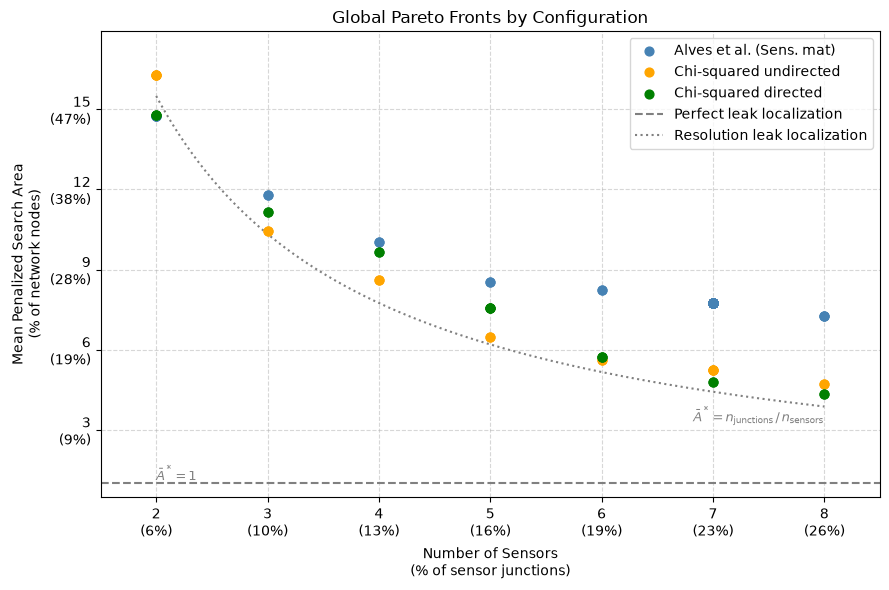

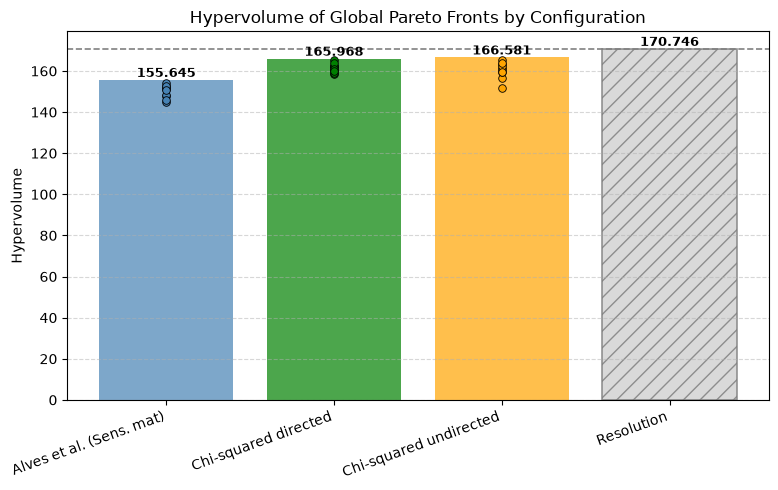

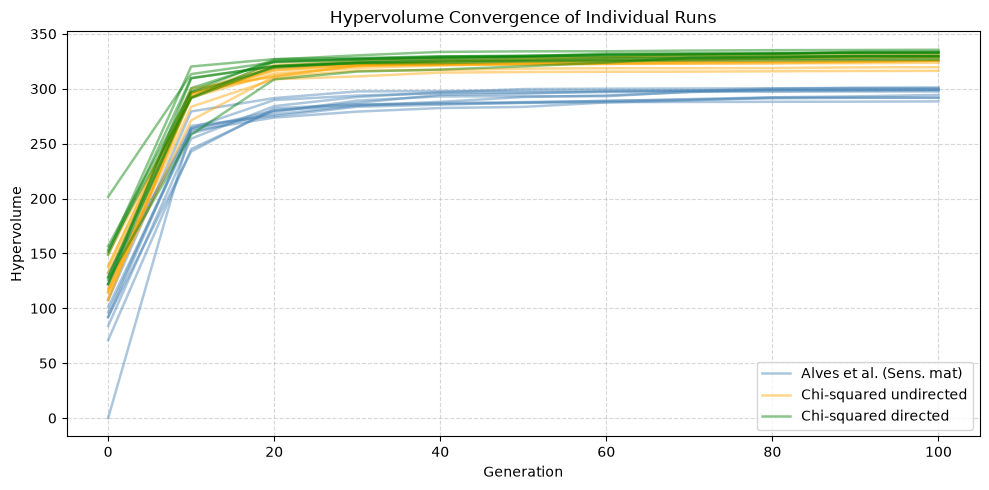

In [5]:
results = [suggested_res, scaled_chisq_res, scaled_chisq_dir_res]
labels = ["Alves et al. (Sens. mat)", "Chi-squared undirected", "Chi-squared directed"]
colors = ["steelblue", "orange", "green", "purple"]

# 1. Pareto front scatter
fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)

# 2. Parallel coordinates of all objectives (normalised to [0,1])
#fig, ax = plot_parallel_coordinates(results, labels, colors)

# 3. Hypervolume bar — max HV across islands at final generation
fig, ax = plot_hypervolume_bar(results, labels, colors)

# 4a. Hypervolume per island across generations
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** Like when using the Boatwright LSM reconstruction method, using the scaled chi-squared matrix instead of the plain sensitivity matrix impproves the LL method's performances.